# Part 5 — Efficient Data Handling through Data Parallelism
**Data parallelism** = split the data into partitions and run the *same* operation on every partition at the
same time, then combine the small partial results. Spark does this automatically; this notebook shows *how*,
measures it, and tunes it.

Machine: MacBook Air M2 (8 cores, 8 GB RAM). Spark runs `local[4]` → **4 executor threads = 4 tasks in parallel**.
Because `bank.csv` is tiny (4,521 rows), some experiments also use a **50× scaled copy (226,050 rows)** so that
parallelism effects are measurable instead of being hidden by scheduling overhead.

In [1]:
import os, sys, time
# Spark needs Java 17; point to Homebrew's JDK if JAVA_HOME is not already set
os.environ.setdefault("JAVA_HOME", "/opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home")
os.environ["PYSPARK_PYTHON"] = sys.executable          # workers use this venv's Python
os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")    # single machine: bind to localhost
os.chdir(os.path.dirname(os.path.abspath("__file__")) if os.path.exists("data") else "..")

from pyspark.sql import SparkSession, functions as F, types as T

spark = (SparkSession.builder
         .appName("Bank-DataParallelism")
         .master("local[4]")                          # 4 worker threads = 4 parallel tasks
         .config("spark.driver.memory", "2g")
         .config("spark.sql.shuffle.partitions", "8")  # small data -> fewer shuffle partitions
         .config("spark.hadoop.fs.defaultFS", "file:///")  # read local files even if HADOOP_CONF_DIR is set
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.scheduler.mode", "FAIR")      # lets concurrent jobs share the 4 cores fairly
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
DATA = "data/bank.csv"
print("Spark", spark.version, "| master:", spark.sparkContext.master,
      "| default parallelism:", spark.sparkContext.defaultParallelism)
print("Spark UI (while this notebook runs): http://localhost:4040")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/25 11:02:08 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.0.1 | master: local[4] | default parallelism: 4
Spark UI (while this notebook runs): http://localhost:4040


In [2]:
# Resource monitor: samples CPU and memory of the whole machine and of the Spark JVM every 0.5 s
import threading, psutil, pandas as pd
import matplotlib.pyplot as plt

class ResourceMonitor:
    def __init__(self, interval=0.5):
        self.interval, self.samples, self.marks = interval, [], []
        self._stop = threading.Event()
        me = psutil.Process()
        self.jvm = next((c for c in me.children(recursive=True) if "java" in c.name().lower()), None)
    def _run(self):
        t0 = time.time()
        psutil.cpu_percent(percpu=True)
        while not self._stop.is_set():
            time.sleep(self.interval)
            cores = psutil.cpu_percent(percpu=True)
            self.samples.append({"t": time.time() - t0, "cpu_total_pct": sum(cores) / len(cores),
                                 "busy_cores": sum(c > 50 for c in cores),
                                 "jvm_cpu_pct": self.jvm.cpu_percent() if self.jvm else None,
                                 "jvm_rss_mb": self.jvm.memory_info().rss / 2**20 if self.jvm else None,
                                 "ram_used_pct": psutil.virtual_memory().percent})
        self.t0 = t0
    def start(self):
        self._t0 = time.time(); self.thread = threading.Thread(target=self._run, daemon=True); self.thread.start(); return self
    def mark(self, label):
        self.marks.append((time.time() - self._t0, label))
    def stop(self):
        self._stop.set(); self.thread.join(); return pd.DataFrame(self.samples)

monitor = ResourceMonitor().start()
monitor.mark("start")
print("monitoring Spark JVM pid:", monitor.jvm.pid if monitor.jvm else "not found")

monitoring Spark JVM pid: 72930


## 1. Data preparation and partitioning

In [3]:
df = spark.read.csv(DATA, header=True, inferSchema=True)
df.show(5)
print("rows:", df.count(), "| partitions after reading:", df.rdd.getNumPartitions())

+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|age|        job|marital|education|default|balance|housing|loan| contact|day|month|duration|campaign|pdays|previous|poutcome|  y|
+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
| 30| unemployed|married|  primary|     no|   1787|     no|  no|cellular| 19|  oct|      79|       1|   -1|       0| unknown| no|
| 33|   services|married|secondary|     no|   4789|    yes| yes|cellular| 11|  may|     220|       1|  339|       4| failure| no|
| 35| management| single| tertiary|     no|   1350|    yes|  no|cellular| 16|  apr|     185|       1|  330|       1| failure| no|
| 30| management|married| tertiary|     no|   1476|    yes| yes| unknown|  3|  jun|     199|       4|   -1|       0| unknown| no|
| 59|blue-collar|married|secondary|     no|      0|    yes|  no| unknown|  5|  may|     22

rows: 4521 | partitions after reading: 1


A 367 KB file is read as **one** partition (Spark's default split size is 128 MB), so by default only
**one** of the 4 cores would work on it. We compare three partitioning strategies:

In [4]:
from pyspark.sql.functions import spark_partition_id

def partition_sizes(d):
    return [r["count"] for r in d.groupBy(spark_partition_id().alias("pid")).count().orderBy("pid").collect()]

strategies = {
    "default (as read)":              df,
    "round-robin  repartition(8)":    df.repartition(8),
    "hash by job  repartition(8,job)": df.repartition(8, "job"),
    "range by balance  (8)":          df.repartitionByRange(8, "balance"),
}
for name, d in strategies.items():
    sizes = partition_sizes(d)
    print(f"{name:33s} partitions={d.rdd.getNumPartitions():2d}  rows per partition={sizes}")

default (as read)                 partitions= 1  rows per partition=[4521]


round-robin  repartition(8)       partitions= 8  rows per partition=[565, 565, 566, 565, 565, 565, 565, 565]


hash by job  repartition(8,job)   partitions= 8  rows per partition=[1447, 230, 667, 1129, 880, 168]


range by balance  (8)             partitions= 8  rows per partition=[723, 445, 579, 525, 604, 537, 546, 562]


In [5]:
# which jobs ended up together under hash partitioning?
(df.repartition(8, "job").withColumn("pid", spark_partition_id())
   .groupBy("pid").agg(F.collect_set("job").alias("jobs_in_partition"), F.count("*").alias("rows"))
   .orderBy("pid").show(truncate=False))

+---+----------------------------------------+----+
|pid|jobs_in_partition                       |rows|
+---+----------------------------------------+----+
|1  |[management, admin.]                    |1447|
|3  |[retired]                               |230 |
|4  |[services, unemployed, student, unknown]|667 |
|5  |[blue-collar, self-employed]            |1129|
|6  |[technician, housemaid]                 |880 |
|7  |[entrepreneur]                          |168 |
+---+----------------------------------------+----+



**Strategy chosen: hash partitioning on `job` into 8 partitions (2 × the 4 cores).**
* Every row of one job lands in the **same partition**, so a `groupBy("job")` needs **no further shuffle** —
  Spark can reuse the existing partitioning (see the plans below).
* 8 partitions = 2 tasks per core, so a slow partition does not leave other cores idle at the end.
* Trade-off: hash partitioning on a skewed key creates **uneven partitions** (management/blue-collar are big,
  some partitions hold 2 small jobs). Round-robin is perfectly balanced but forces a shuffle for every
  `groupBy("job")`; range partitioning suits sorting/range filters on `balance`.

In [6]:
by_job = df.repartition(8, "job").cache()
by_job.count()
print("--- groupBy on round-robin data: needs an Exchange (shuffle) ---")
df.repartition(8).groupBy("job").agg(F.avg("balance")).explain()
print("--- groupBy on data already hash-partitioned by job: no extra Exchange ---")
by_job.groupBy("job").agg(F.avg("balance")).explain()

--- groupBy on round-robin data: needs an Exchange (shuffle) ---


== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[job#18], functions=[avg(balance#22)])
   +- Exchange hashpartitioning(job#18, 8), ENSURE_REQUIREMENTS, [plan_id=709]
      +- HashAggregate(keys=[job#18], functions=[partial_avg(balance#22)])
         +- Exchange RoundRobinPartitioning(8), REPARTITION_BY_NUM, [plan_id=705]
            +- FileScan csv [job#18,balance#22] Batched: false, DataFilters: [], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/Users/pranati/bank-distributed-ml/data/bank.csv], PartitionFilters: [], PushedFilters: [], ReadSchema: struct<job:string,balance:int>


--- groupBy on data already hash-partitioned by job: no extra Exchange ---
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[job#18], functions=[avg(balance#22)])
   +- HashAggregate(keys=[job#18], functions=[partial_avg(balance#22)])
      +- InMemoryTableScan [job#18, balance#22]
            +- InMemoryRelation [age#17, job#18, marital#19, e

## 2. Data analysis and processing in parallel
### 2a. Average balance per job — two parallel approaches

In [7]:
monitor.mark("avg balance per job")
# (1) DataFrame API: each partition computes partial (sum, count) per job -> shuffle -> final average
t0 = time.time()
avg_df = by_job.groupBy("job").agg(F.round(F.avg("balance"), 2).alias("avg_balance"),
                                   F.count("*").alias("clients")).orderBy(F.desc("avg_balance"))
avg_df.show()
print(f"DataFrame groupBy: {time.time() - t0:.2f}s")

# (2) RDD API, written out explicitly: map -> combine locally per partition -> reduceByKey across partitions
t0 = time.time()
rdd = by_job.select("job", "balance").rdd
partials = rdd.map(lambda r: (r.job, (r.balance, 1)))                      # runs on every partition in parallel
totals = partials.reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))       # combines inside partitions first
avg_rdd = sorted(((j, round(s / c, 2)) for j, (s, c) in totals.collect()), key=lambda x: -x[1])
print(f"RDD reduceByKey:   {time.time() - t0:.2f}s")
print(avg_rdd)

+-------------+-----------+-------+
|          job|avg_balance|clients|
+-------------+-----------+-------+
|      retired|    2319.19|    230|
|    housemaid|     2083.8|    112|
|   management|    1766.93|    969|
| entrepreneur|    1645.13|    168|
|      student|    1543.82|     84|
|      unknown|    1501.71|     38|
|self-employed|    1392.41|    183|
|   technician|     1331.0|    768|
|       admin.|    1226.74|    478|
|     services|    1103.96|    417|
|   unemployed|    1089.42|    128|
|  blue-collar|    1085.16|    946|
+-------------+-----------+-------+

DataFrame groupBy: 0.14s


RDD reduceByKey:   0.65s
[('retired', 2319.19), ('housemaid', 2083.8), ('management', 1766.93), ('entrepreneur', 1645.12), ('student', 1543.82), ('unknown', 1501.71), ('self-employed', 1392.41), ('technician', 1331.0), ('admin.', 1226.74), ('services', 1103.96), ('unemployed', 1089.42), ('blue-collar', 1085.16)]


In [8]:
# Show the work each partition did in parallel (partition id -> jobs and partial sums)
def per_partition(idx, it):
    acc = {}
    for r in it:
        s, c = acc.get(r.job, (0, 0)); acc[r.job] = (s + r.balance, c + 1)
    yield (idx, {k: v[1] for k, v in acc.items()})
for pid, jobs in rdd.mapPartitionsWithIndex(per_partition).collect():
    print(f"partition {pid}: rows per job {jobs}")

partition 0: rows per job {}
partition 1: rows per job {'management': 969, 'admin.': 478}
partition 2: rows per job {}
partition 3: rows per job {'retired': 230}
partition 4: rows per job {'unemployed': 128, 'services': 417, 'student': 84, 'unknown': 38}
partition 5: rows per job {'blue-collar': 946, 'self-employed': 183}
partition 6: rows per job {'technician': 768, 'housemaid': 112}
partition 7: rows per job {'entrepreneur': 168}


### 2b. Top 5 age groups with the highest loan amounts
**Data note:** `bank.csv` has no loan *amount* column — `housing` and `loan` are only yes/no flags. So we measure
**loan volume** as the number of loans held (housing + personal) per 5-year age group, and also report the total
and average account balance of the loan holders in each group as a size proxy.

In [9]:
monitor.mark("loans per age group")
loans = (df.repartition(8)                                     # spread the work over all cores
           .withColumn("age_group", F.concat((F.floor(F.col("age") / 5) * 5).cast("int").cast("string"), F.lit("-"),
                                             (F.floor(F.col("age") / 5) * 5 + 4).cast("int").cast("string")))
           .withColumn("n_loans", (F.col("housing") == "yes").cast("int") + (F.col("loan") == "yes").cast("int")))
top5 = (loans.groupBy("age_group")
        .agg(F.count("*").alias("clients"),
             F.sum("n_loans").alias("total_loans"),
             F.sum((F.col("housing") == "yes").cast("int")).alias("housing_loans"),
             F.sum((F.col("loan") == "yes").cast("int")).alias("personal_loans"),
             F.round(F.avg("n_loans"), 2).alias("loans_per_client"),
             F.sum(F.when(F.col("n_loans") > 0, F.col("balance"))).alias("balance_of_loan_holders"))
        .orderBy(F.desc("total_loans")).limit(5))
top5.show()

+---------+-------+-----------+-------------+--------------+----------------+-----------------------+
|age_group|clients|total_loans|housing_loans|personal_loans|loans_per_client|balance_of_loan_holders|
+---------+-------+-----------+-------------+--------------+----------------+-----------------------+
|    30-34|    990|        807|          636|           171|            0.82|                 801276|
|    35-39|    818|        614|          514|           100|            0.75|                 716686|
|    40-44|    638|        515|          414|           101|            0.81|                 629202|
|    45-49|    565|        395|          312|            83|             0.7|                 386949|
|    25-29|    415|        306|          247|            59|            0.74|                 251174|
+---------+-------+-----------+-------------+--------------+----------------+-----------------------+



**Methodology:** derive `age_group` and `n_loans` per row (embarrassingly parallel — every partition works
alone), then `groupBy` does a partial aggregation in each of the 8 partitions and one small shuffle to merge them.

## 3. Model training on partitioned data
**Model: Logistic Regression.** Reasons: (1) its training is naturally data-parallel — every iteration each
partition computes the gradient on its own rows and Spark sums them with a `treeAggregate`; (2) it was the best
model in Part 3 (AUC ≈ 0.90); (3) its coefficients are interpretable for the business.

In [10]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator

cats = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]
nums = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
feat_pipe = Pipeline(stages=[*[StringIndexer(inputCol=c, outputCol=c + "_i", handleInvalid="keep") for c in cats],
                             OneHotEncoder(inputCols=[c + "_i" for c in cats], outputCols=[c + "_o" for c in cats]),
                             VectorAssembler(inputCols=nums + [c + "_o" for c in cats], outputCol="features")])
data = (feat_pipe.fit(df).transform(df.withColumn("label", (F.col("y") == "yes").cast("double")))
        .select("features", "label"))
train, test = data.randomSplit([0.8, 0.2], seed=42)
train = train.repartition(4).cache(); test = test.cache()
print("train partitions:", train.rdd.getNumPartitions(), "| rows per partition:", partition_sizes(train))

monitor.mark("train LR (4 partitions)")
lr = LogisticRegression(maxIter=50, regParam=0.01)
t0 = time.time(); model = lr.fit(train); secs = time.time() - t0
auc = BinaryClassificationEvaluator(rawPredictionCol="probability").evaluate(model.transform(test))
print(f"trained in {secs:.2f}s on {train.rdd.getNumPartitions()} partitions | iterations: {model.summary.totalIterations} | test AUC = {auc:.4f}")

train partitions: 4 | rows per partition: [915, 916, 916, 915]


trained in 1.25s on 4 partitions | iterations: 22 | test AUC = 0.8819


### Does more parallelism make training faster? — scaling experiment
To see real effects we scale the data 50× (226k rows) and train the same model with 1, 2, 4, 8 and 32 partitions.

In [11]:
big = data.crossJoin(spark.range(50).withColumnRenamed("id", "copy")).drop("copy")
print("scaled training data rows:", big.count())
monitor.mark("scaling experiment")
timings = []
for n in [1, 2, 4, 8, 32]:
    part = big.repartition(n).cache(); part.count()               # materialise before timing
    t0 = time.time()
    LogisticRegression(maxIter=20, regParam=0.01, tol=0.0).fit(part)
    timings.append({"partitions": n, "train_sec": round(time.time() - t0, 2)})
    part.unpersist()
timing_df = pd.DataFrame(timings)
timing_df["speedup_vs_1"] = (timing_df.train_sec.iloc[0] / timing_df.train_sec).round(2)
timing_df

scaled training data rows: 226050


,partitions,train_sec,speedup_vs_1
0,1,1.15,1.00
1,2,0.63,1.83
2,4,0.54,2.13
3,8,0.75,1.53
4,32,1.18,0.97


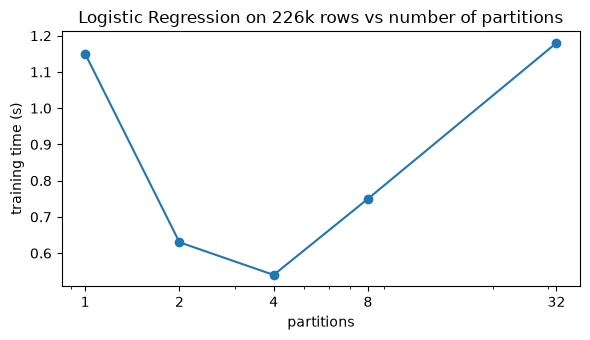

In [12]:
ax = timing_df.plot(x="partitions", y="train_sec", marker="o", logx=True, legend=False, figsize=(6, 3.5))
ax.set_xticks(timing_df.partitions); ax.set_xticklabels(timing_df.partitions)
ax.set_ylabel("training time (s)"); ax.set_title("Logistic Regression on 226k rows vs number of partitions")
plt.tight_layout(); plt.savefig("docs/figures/partitions_vs_training_time.png", dpi=120); plt.show()

**Challenges and how they were handled**
* **Too few partitions** (1 partition after reading) → only one core busy. Fixed with `repartition(4/8)`.
* **Too many partitions** (32) → each task is tiny and the per-task scheduling + `treeAggregate` overhead grows,
  so time stops improving or gets worse. Rule of thumb used: **2–3 partitions per core**.
* **Re-reading data every iteration** — LR makes many passes, so the training set is `cache()`d once.
* **Class imbalance & reproducibility** — fixed seeds for the split; class weights were covered in Part 3.
* **Python UDFs** would move rows between JVM and Python and break the speed-up, so only built-in functions are used.

## 4. Resource monitoring and management

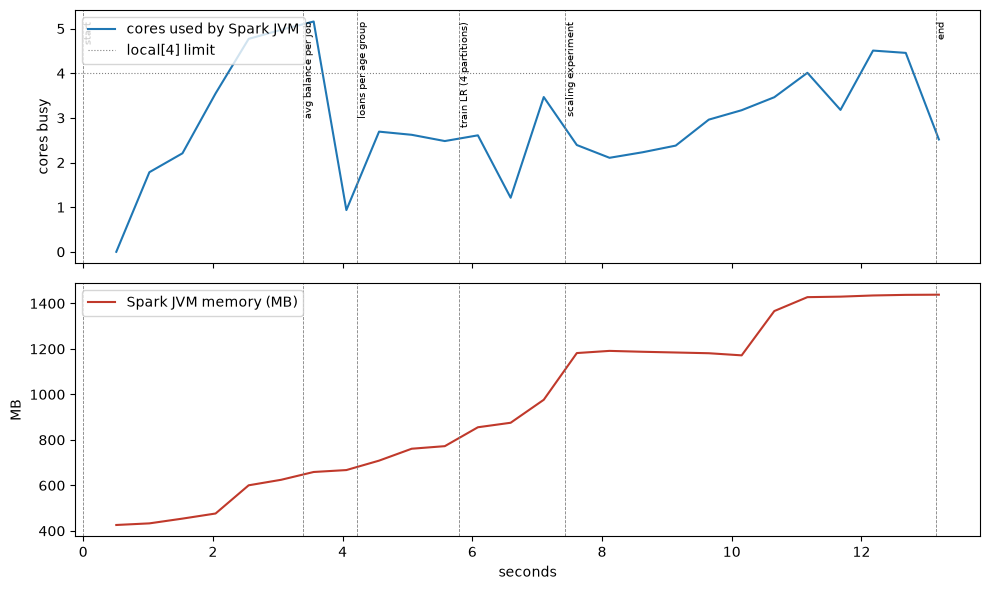

,seconds,avg_spark_cores,peak_spark_cores,peak_jvm_mb,machine_cpu_pct
phase,,,,,
start,3.0,2.88,4.97,624.52,84.36
avg balance per job,1.0,3.05,5.16,667.25,85.29
loans per age group,1.5,2.60,2.69,772.36,81.98
train LR (4 partitions),1.5,2.43,3.47,976.27,75.09
scaling experiment,5.5,3.17,4.51,1437.50,80.32
end,0.5,2.52,2.52,1438.27,77.46


peak Spark JVM memory: 1438 MB | peak cores used by Spark: 5.2 of 4 | machine RAM used: 77%


In [13]:
monitor.mark("end")
res = monitor.stop()
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
a1.plot(res.t, res.jvm_cpu_pct / 100, label="cores used by Spark JVM")
a1.axhline(4, color="grey", lw=0.8, ls=":", label="local[4] limit")
a1.set_ylabel("cores busy"); a1.legend(loc="upper left")
a2.plot(res.t, res.jvm_rss_mb, color="#c0392b", label="Spark JVM memory (MB)")
a2.set_ylabel("MB"); a2.set_xlabel("seconds"); a2.legend(loc="upper left")
for t, label in monitor.marks:
    for a in (a1, a2):
        a.axvline(t, color="grey", lw=0.6, ls="--")
    a1.annotate(label, (t, a1.get_ylim()[1] * 0.95), rotation=90, fontsize=7, va="top")
plt.tight_layout(); plt.savefig("docs/figures/resource_usage.png", dpi=120); plt.show()

phase = res.assign(phase=pd.cut(res.t, [m[0] for m in monitor.marks] + [res.t.max() + 1],
                                labels=[m[1] for m in monitor.marks], right=False))
phase["spark_cores_used"] = phase.jvm_cpu_pct / 100          # JVM CPU% / 100 = cores Spark keeps busy
summary = phase.groupby("phase", observed=True).agg(seconds=("t", lambda x: len(x) * monitor.interval),
        avg_spark_cores=("spark_cores_used", "mean"), peak_spark_cores=("spark_cores_used", "max"),
        peak_jvm_mb=("jvm_rss_mb", "max"), machine_cpu_pct=("cpu_total_pct", "mean")).round(2)
display(summary)
print(f"peak Spark JVM memory: {res.jvm_rss_mb.max():.0f} MB | peak cores used by Spark: "
      f"{phase.spark_cores_used.max():.1f} of 4 | machine RAM used: {res.ram_used_pct.max():.0f}%")

In [14]:
# Spark's own view: executor memory and task counters from the status API (same data as the Spark UI)
import json, urllib.request
ui = spark.sparkContext.uiWebUrl
app_id = spark.sparkContext.applicationId
ex = json.load(urllib.request.urlopen(f"{ui}/api/v1/applications/{app_id}/executors"))
for e in ex:
    print(f"executor {e['id']}: cores={e['totalCores']}  tasks done={e['completedTasks']}  "
          f"storage memory used={e['memoryUsed']/2**20:.1f} MB of {e['maxMemory']/2**20:.0f} MB  "
          f"total task time={e['totalDuration']/1000:.0f}s  GC time={e['totalGCTime']/1000:.1f}s")
sm = spark.sparkContext.statusTracker()
print("active jobs right now:", sm.getActiveJobsIds())

executor driver: cores=4  tasks done=1633  storage memory used=113.5 MB of 1049 MB  total task time=16s  GC time=0.3s
active jobs right now: []


**Observations**
* CPU is measured for the **Spark JVM itself** (JVM CPU% ÷ 100 = cores in use), so other apps do not distort it.
* Short actions on the single-partition input keep only ~1 core busy; the repartitioned aggregation, the training
  and especially the 50× scaling experiment drive Spark towards its **4-core limit** (`local[4]`).
* `local[4]` caps Spark at **4 task threads** even though the M2 has 8 cores, leaving room for the OS, VS Code and
  the notebook kernel. Peaks slightly above 4 cores are the JVM's own garbage-collection and JIT-compiler threads
  running next to the 4 tasks.
* Spark JVM memory grows in steps when data is `cache()`d — from ~0.6 GB at start to ~1.3 GB during the 50× scaling
  experiment — and does not drop straight away after `unpersist()` (the JVM keeps its heap). Caching trades memory
  for speed; with 8 GB RAM the driver is capped at 2 GB and each experiment releases its cache.
* GC time is small compared to task time, so memory is not the bottleneck at this data size.

## 5. Task management and scheduling
Several independent preprocessing tasks are submitted **at the same time** from Python threads. Spark's
**FAIR scheduler** (enabled in the SparkSession above) shares the 4 cores between them, and each task is tagged
with a **job group** and **scheduler pool** so it can be tracked (and cancelled) in the Spark UI.

In [15]:
from concurrent.futures import ThreadPoolExecutor
big_raw = df.crossJoin(spark.range(50).withColumnRenamed("id", "copy")).drop("copy").repartition(8).cache()
big_raw.count()
sc = spark.sparkContext

def task_null_report():
    return big_raw.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in big_raw.columns]).collect()
def task_iqr_caps():
    return big_raw.approxQuantile(["balance", "duration", "campaign"], [0.25, 0.75], 0.001)
def task_category_counts():
    return {c: big_raw.groupBy(c).count().count() for c in ["job", "education", "month", "poutcome"]}
def task_job_stats():
    return big_raw.groupBy("job", "marital").agg(F.avg("balance"), F.max("duration")).collect()

tasks = {"null_report": task_null_report, "iqr_caps": task_iqr_caps,
         "category_counts": task_category_counts, "job_stats": task_job_stats}

def run(name):
    sc.setLocalProperty("spark.scheduler.pool", name)          # own FAIR pool per task
    sc.setJobGroup(name, f"preprocessing task: {name}")       # visible + cancellable in the Spark UI
    t0 = time.time(); tasks[name](); return name, round(time.time() - t0, 2)

t0 = time.time(); seq = [run(n) for n in tasks]; seq_total = time.time() - t0
t0 = time.time()
with ThreadPoolExecutor(max_workers=4) as pool:
    conc = list(pool.map(run, tasks))
conc_total = time.time() - t0
sc.setLocalProperty("spark.scheduler.pool", None); sc.setJobGroup("", "")
print(pd.DataFrame({"task": [s[0] for s in seq], "sequential_s": [s[1] for s in seq],
                    "concurrent_s": [c[1] for c in conc]}).to_string(index=False))
print(f"\nall 4 tasks: sequential {seq_total:.2f}s  vs  concurrent {conc_total:.2f}s "
      f"-> {seq_total / conc_total:.2f}x faster")
_ = big_raw.unpersist()

           task  sequential_s  concurrent_s
    null_report          0.33          0.19
       iqr_caps          0.31          0.22
category_counts          0.25          0.26
      job_stats          0.13          0.13

all 4 tasks: sequential 1.02s  vs  concurrent 0.27s -> 3.85x faster


**How tasks were managed effectively**
* **Concurrency:** independent tasks run in parallel threads instead of waiting for each other; Spark interleaves
  their stages on the free cores.
* **Fairness:** `spark.scheduler.mode=FAIR` + one pool per task stops a long task from starving short ones
  (the default FIFO scheduler would run them strictly one after another).
* **Visibility & control:** `setJobGroup` labels every Spark job, so the Jobs tab shows which task each job belongs
  to, and `sc.cancelJobGroup(name)` can stop one task without killing the others.
* **Shared cached input:** all four tasks read the same cached DataFrame, so the data is loaded once.
* **Right-sizing:** 8 partitions for 4 cores keeps every core busy without drowning in tiny tasks.

In [16]:
spark.stop()